# Resonance Overlap: When Do Two Close Planets Become Chaotic?

*Matthew Payne*

The *Kepler* mission found many systems of planets on nearly circular, nearly coplanar orbits, packed so closely that neighbouring period ratios lie between 1 and 2. How close can two planets be and still remain stable for billions of years?

This notebook reproduces, with direct numerical experiments, the main results of

> K. M. Deck, M. Payne & M. J. Holman (2013), *First-order Resonance Overlap and the Stability of Close Two-planet Systems*, ApJ **774**, 129. [ADS](https://ui.adsabs.harvard.edu/abs/2013ApJ...774..129D/abstract) · [arXiv:1307.8119](https://arxiv.org/abs/1307.8119)

We will:

1. See why first-order mean motion resonances must overlap when two planets are close enough, and where that happens.
2. Map chaos numerically in the plane of period ratio and eccentricity, and compare it with the analytic overlap criteria.
3. Measure the edge of the chaotic zone for initially circular orbits across four decades of planet mass, and compare it with the Hill stability boundary.
4. Show that an orbit can be Hill stable and still be unstable: its period ratio wanders erratically through the chaotic web.

**Requirements:** `numpy`, `matplotlib` and `rebound` (version 4 or later). The grids below take about two minutes on a 12-core laptop; set `QUICK = True` for a coarse version that runs in seconds.

In [1]:
import os
import time
from multiprocessing import Pool

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

import overlap as ov   # helper module in this folder: criteria and integrations

QUICK = False          # True: coarse grids for a fast first look
NPROC = os.cpu_count()
print(f"Using {NPROC} processes; QUICK = {QUICK}")

# Regular / chaotic / unstable, used in every map below
CLASS_CMAP = ListedColormap(["#dfe8ea", "#1f6f8b", "#e9a160"])
CLASS_LABELS = ["regular (MEGNO ≈ 2)", "chaotic (MEGNO > 4)", "unstable (scattered)"]

Using 12 processes; QUICK = False


## Two Classic Answers

Write $\epsilon_p = (m_1+m_2)/M_\star$ for the total planetary mass relative to the star, and $\Delta = (a_2-a_1)/a_1$ for the fractional separation of the orbits.

**Hill stability.** Conservation of energy and angular momentum can forbid the two orbits from ever crossing ([Marchal & Bozis 1982](https://ui.adsabs.harvard.edu/abs/1982CeMec..26..311M/abstract); [Gladman 1993](https://ui.adsabs.harvard.edu/abs/1993Icar..106..247G/abstract)). For initially circular orbits this holds when

$$\Delta \gtrsim 2.4\,\epsilon_p^{1/3}.$$

A Hill-stable pair can never have a close encounter. But the criterion says nothing about whether the orbits themselves stay put.

**Resonance overlap.** When two independent resonances overlap, motion between them becomes chaotic ([Chirikov 1979](https://ui.adsabs.harvard.edu/abs/1979PhR....52..263C/abstract)). [Wisdom (1980)](https://ui.adsabs.harvard.edu/abs/1980AJ.....85.1122W/abstract) applied this to a test particle near a planet and found chaos for $\Delta \lesssim 1.3\,\epsilon^{2/7}$. Deck, Payne & Holman (2013) extended the calculation to **two massive planets**, by reducing the Hamiltonian near a first-order resonance to one degree of freedom. For initially circular orbits they find overlap, and widespread chaos, when

$$\Delta \lesssim 1.46\,\epsilon_p^{2/7}, \qquad\text{equivalently}\qquad \frac{P_2}{P_1} \lesssim 1 + 2.2\,\epsilon_p^{2/7}.$$

At lowest order the planetary mass ratio $m_1/m_2$ drops out, so only the total mass matters.

## 1. Why Overlap Is Inevitable

The first-order resonances sit at period ratios $P_2/P_1 = (m+1)/m$: 2:1, 3:2, 4:3, and so on. Two things happen as $m$ grows and the resonances crowd towards $P_2/P_1 = 1$:

* **They get closer together.** In $\alpha = a_1/a_2$, neighbouring resonances are separated by $\Delta\alpha/\alpha \approx 2/(3m^2)$.
* **They get wider.** For circular orbits, DPH13 find each resonance has a full width $\delta\alpha/\alpha \approx 4.18\,\epsilon_p^{2/3} m^{1/3}$.

Spacing falls as $m^{-2}$ while width grows as $m^{1/3}$, so beyond some $m$ every resonance touches its neighbour. Setting spacing equal to width gives $m \approx 0.455\,\epsilon_p^{-2/7}$, which is where the criterion above comes from.

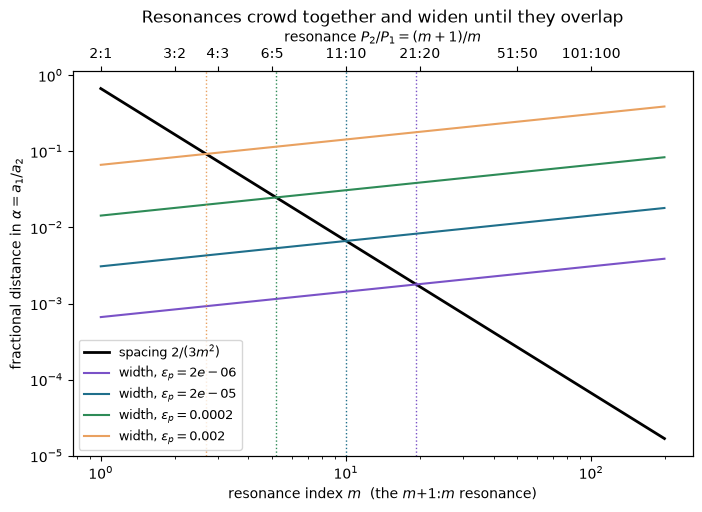

eps_p = 2e-06:  overlap beyond m ≈  19.3,  i.e. P2/P1 < 1.052
eps_p = 2e-05:  overlap beyond m ≈  10.0,  i.e. P2/P1 < 1.100
eps_p = 0.0002:  overlap beyond m ≈   5.2,  i.e. P2/P1 < 1.193
eps_p = 0.002:  overlap beyond m ≈   2.7,  i.e. P2/P1 < 1.373


In [2]:
m = np.arange(1, 200)
fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(m, ov.resonance_spacing(m), color="black", lw=2, label=r"spacing $2/(3m^2)$")
for eps, col in [(2e-6, "#7a52c7"), (2e-5, "#1f6f8b"), (2e-4, "#2e8b57"), (2e-3, "#e9a160")]:
    ax.loglog(m, ov.resonance_full_width(eps, m), color=col, label=rf"width, $\epsilon_p = {eps:g}$")
    m_crit = 0.455 * eps ** (-2 / 7)
    ax.axvline(m_crit, color=col, ls=":", lw=1)
ax.set_xlabel("resonance index $m$  (the $m{+}1$:$m$ resonance)")
ax.set_ylabel(r"fractional distance in $\alpha = a_1/a_2$")
ax.set_title("Resonances crowd together and widen until they overlap")
ax.legend(fontsize=9)
# Label the top axis with the period ratio (m+1)/m of a few resonances
top = ax.twiny()
top.set_xscale("log"); top.set_xlim(ax.get_xlim())
ticks = [1, 2, 3, 5, 10, 20, 50, 100]
top.set_xticks(ticks, [f"{(t + 1)}:{t}" for t in ticks]); top.minorticks_off()
top.set_xlabel("resonance $P_2/P_1 = (m+1)/m$")
plt.show()

for eps in [2e-6, 2e-5, 2e-4, 2e-3]:
    print(f"eps_p = {eps:g}:  overlap beyond m ≈ {0.455 * eps ** (-2 / 7):5.1f},  "
          f"i.e. P2/P1 < {ov.overlap_period_ratio_circular(eps):.3f}")

The dotted lines mark where each width curve crosses the spacing. For two Jupiter-mass planets ($\epsilon_p \approx 2\times10^{-3}$) overlap begins near the 4:3 resonance. For two Earths around a Sun-like star ($\epsilon_p \approx 6\times10^{-6}$), resonances do not overlap until about $P_2/P_1 \approx 1.07$.

This is a lowest-order estimate: it ignores second- and higher-order resonances, whose own chaotic layers join neighbouring first-order resonances before they touch. The criterion is therefore a *minimum* extent for chaos. Now let's test it numerically.

## 2. Mapping Chaos in Period Ratio and Eccentricity

We integrate two equal-mass planets with $\epsilon_p = 2\times10^{-5}$ (about 3.3 Earth masses each around a Sun-like star) over a grid of initial period ratios and inner eccentricities $e_1$. The outer orbit starts circular, so the paper's weighted eccentricity is simply $\sigma = e_1$. All angles start at zero except the inner planet's mean anomaly, $M_1 = \pi/2$. This is the set-up of one panel of the paper's Figure 5 (figure numbers follow the arXiv version).

Each run uses REBOUND's symplectic WHFast integrator with 40 steps per inner orbit, and tracks the **MEGNO** chaos indicator, which tends to 2 for regular orbits and grows without bound for chaotic ones. We call an orbit chaotic if MEGNO exceeds 4. Runs where the planets scatter (the period ratio drifts by more than 5%, or an eccentricity exceeds 0.3) are classed as unstable.

Overlaid are three curves:
* the circular-orbit overlap criterion $P_2/P_1 = 1 + 2.2\,\epsilon_p^{2/7}$, drawn where it should apply, $\sigma \lesssim 1.33\,\epsilon_p^{3/7}$;
* the paper's eccentric-orbit estimate $P_2/P_1 = 1 + 2.08\,(\epsilon_p\sigma)^{1/5}$, valid above that $\sigma$;
* the Hill boundary for circular orbits.

In [3]:
EPS = 2e-5
N_ORBITS = 3000
prs = np.linspace(1.04, 1.5, 50 if QUICK else 160)
e1s = np.linspace(0.0, 0.10, 20 if QUICK else 60)
jobs = [(EPS, p, e, N_ORBITS) for e in e1s for p in prs]

t0 = time.time()
with Pool(NPROC) as pool:
    result = pool.map(ov.classify, jobs, chunksize=8)
cls = np.array([c for c, _ in result]).reshape(len(e1s), len(prs))
print(f"{len(jobs)} integrations of {N_ORBITS} orbits in {time.time() - t0:.0f} s")
print("fraction regular / chaotic / unstable:", np.round([np.mean(cls == k) for k in range(3)], 3))

9600 integrations of 3000 orbits in 89 s
fraction regular / chaotic / unstable: [0.684 0.079 0.237]


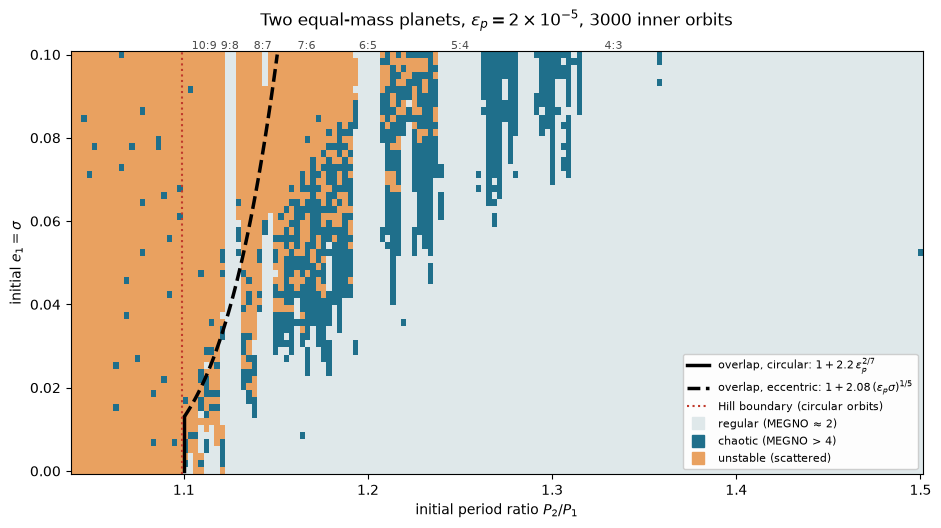

In [4]:
def class_legend(ax, loc="upper right"):
    for k, label in enumerate(CLASS_LABELS):
        ax.scatter([], [], marker="s", s=60, color=CLASS_CMAP(k), label=label)
    ax.legend(loc=loc, fontsize=8, framealpha=0.95)

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.pcolormesh(prs, e1s, cls, cmap=CLASS_CMAP, vmin=-0.5, vmax=2.5, shading="nearest")

sig_switch = 1.33 * EPS ** (3 / 7)
ax.plot([ov.overlap_period_ratio_circular(EPS)] * 2, [0, sig_switch], color="black", lw=2.5,
        label=r"overlap, circular: $1 + 2.2\,\epsilon_p^{2/7}$")
sig = np.linspace(sig_switch, e1s[-1], 100)
ax.plot(ov.overlap_period_ratio_eccentric(EPS, sig), sig, color="black", lw=2.5, ls="--",
        label=r"overlap, eccentric: $1 + 2.08\,(\epsilon_p\sigma)^{1/5}$")
ax.axvline((1 + ov.hill_delta_circular(EPS)) ** 1.5, color="#c0392b", lw=1.5, ls=":",
           label="Hill boundary (circular orbits)")
for j in range(2, 10):   # label the well-separated first-order resonances
    p = (j + 1) / j
    if prs[0] < p < prs[-1]:
        ax.annotate(f"{j + 1}:{j}", (p, e1s[-1]), xytext=(0, 4), textcoords="offset points",
                    ha="center", fontsize=8, color="0.3")
ax.set_xlabel("initial period ratio $P_2/P_1$")
ax.set_ylabel(r"initial $e_1 = \sigma$")
ax.set_title(rf"Two equal-mass planets, $\epsilon_p = 2\times10^{{-5}}$, {N_ORBITS} inner orbits", pad=18)
handles, labels = ax.get_legend_handles_labels()
for k, label in enumerate(CLASS_LABELS):
    handles.append(plt.Line2D([], [], marker="s", ls="", ms=9, color=CLASS_CMAP(k))); labels.append(label)
ax.legend(handles, labels, loc="lower right", fontsize=8, framealpha=0.95)
plt.show()

What the map shows:

* **Near $P_2/P_1 = 1$, essentially everything is chaotic or unstable.** This is the zone of complete first-order overlap, and the circular-orbit criterion marks its edge at low eccentricity.
* **Beyond it lies a chaotic web.** Chaotic bands follow the separatrices of individual resonances. Regular islands survive deep inside the low-order resonances and at low eccentricity between them.
* **The web reaches larger period ratios as eccentricity grows**, because resonance widths grow with $\sigma$. The eccentric estimate follows the trend of the boundary, but the paper notes it is only good to a factor of a few. A sharper eccentric criterion needs second-order resonances too, as the paper concludes and as [Hadden & Lithwick (2018)](https://ui.adsabs.harvard.edu/abs/2018AJ....156...95H/abstract) later developed.

Try changing `M1` in `ov.two_planet_sim`. The paper shows that the initial angles shift the islands but not the overall extent of the chaos.

## 3. The Edge of Chaos Across Planet Masses

The overlap criterion predicts that the chaotic zone for initially circular orbits scales as $\epsilon_p^{2/7}$. The Hill boundary scales as $\epsilon_p^{1/3}$. Because the exponents differ, the two lines must cross, at

$$\epsilon_p = (1.46/2.4)^{21} \approx 3\times10^{-5},$$

about ten Earth masses around a Sun-like star. For heavier planets the Hill criterion is the stricter one. For lighter planets the zone of complete overlap reaches *beyond* the Hill boundary, so even some Hill-stable pairs are chaotic.

We test this by integrating initially circular pairs over a grid of $\epsilon_p$ and $\Delta$, as in the paper's Figure 10. Each run lasts 30 synodic periods (at least 2,000 inner orbits), long enough for chaos to show in the MEGNO.

In [5]:
log_eps = np.linspace(-7, -3, 17 if QUICK else 41)
log_delta = np.linspace(-2.6, -0.6, 25 if QUICK else 71)

def n_orbits_for(delta):
    ratio = (1 + delta) ** 1.5
    synodic = ratio / (ratio - 1)          # synodic period in inner orbits
    return int(max(2000, 30 * synodic))

jobs = [(10 ** le, (1 + 10 ** ld) ** 1.5, 0.0, n_orbits_for(10 ** ld)) for ld in log_delta for le in log_eps]
t0 = time.time()
with Pool(NPROC) as pool:
    result = pool.map(ov.classify, jobs, chunksize=4)
cls2 = np.array([c for c, _ in result]).reshape(len(log_delta), len(log_eps))
print(f"{len(jobs)} integrations in {time.time() - t0:.0f} s")

2911 integrations in 24 s


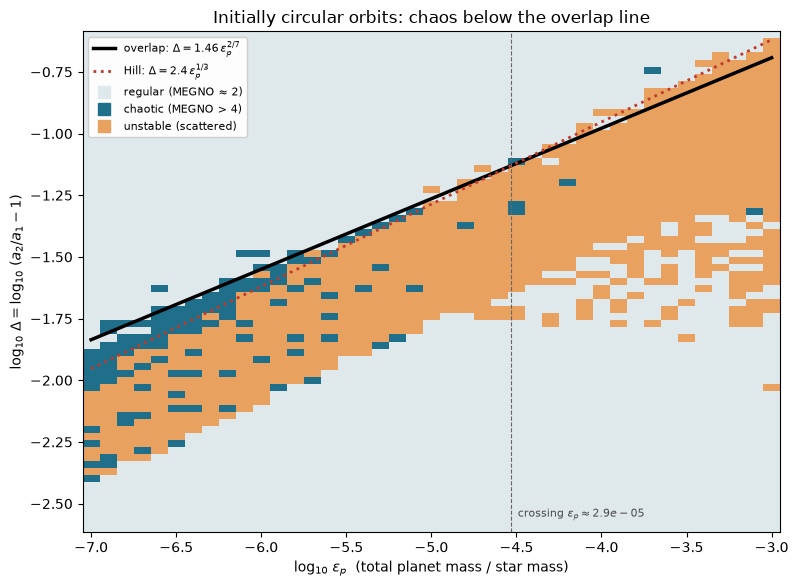

log10(eps)  outermost non-regular log10(Delta)   predicted overlap edge
   -7.0           -1.89                        -1.84
   -6.6           -1.63                        -1.72
   -6.2           -1.60                        -1.61
   -5.8           -1.49                        -1.49
   -5.4           -1.40                        -1.38
   -5.0           -1.23                        -1.26
   -4.6           -1.17                        -1.15
   -4.2           -1.06                        -1.04
   -3.8           -0.91                        -0.92
   -3.4           -0.71                        -0.81
   -3.0           -0.63                        -0.69


In [6]:
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.pcolormesh(log_eps, log_delta, cls2, cmap=CLASS_CMAP, vmin=-0.5, vmax=2.5, shading="nearest")
e = np.logspace(-7, -3, 100)
ax.plot(np.log10(e), np.log10(ov.overlap_delta_circular(e)), color="black", lw=2.5,
        label=r"overlap: $\Delta = 1.46\,\epsilon_p^{2/7}$")
ax.plot(np.log10(e), np.log10(ov.hill_delta_circular(e)), color="#c0392b", lw=2, ls=":",
        label=r"Hill: $\Delta = 2.4\,\epsilon_p^{1/3}$")
cross = (1.46 / 2.4) ** 21
ax.axvline(np.log10(cross), color="0.4", lw=0.8, ls="--")
ax.annotate(rf"crossing $\epsilon_p \approx {cross:.1e}$", (np.log10(cross), log_delta[0]),
            xytext=(5, 8), textcoords="offset points", fontsize=8, color="0.3")
ax.set_xlabel(r"$\log_{10}\,\epsilon_p$  (total planet mass / star mass)")
ax.set_ylabel(r"$\log_{10}\,\Delta = \log_{10}\,(a_2/a_1 - 1)$")
ax.set_title("Initially circular orbits: chaos below the overlap line")
handles, labels = ax.get_legend_handles_labels()
for k, label in enumerate(CLASS_LABELS):
    handles.append(plt.Line2D([], [], marker="s", ls="", ms=9, color=CLASS_CMAP(k))); labels.append(label)
ax.legend(handles, labels, loc="upper left", fontsize=8, framealpha=0.95)
plt.show()

# Where does chaos stop? For each mass, the widest separation that is not regular.
edge = []
for j, le in enumerate(log_eps):
    not_regular = np.where(cls2[:, j] != ov.REGULAR)[0]
    edge.append(log_delta[not_regular].max() if len(not_regular) else np.nan)
edge = np.array(edge)
pred = np.log10(ov.overlap_delta_circular(10 ** log_eps))
print("log10(eps)  outermost non-regular log10(Delta)   predicted overlap edge")
for le, ed, pr_ in list(zip(log_eps, edge, pred))[::4]:
    print(f"  {le:5.1f}          {ed:6.2f}                       {pr_:6.2f}")

The edge of the chaotic zone follows the $\epsilon_p^{2/7}$ overlap line across four decades in mass. At the highest masses the line slightly underestimates the chaotic zone, whose edge instead tracks the Hill boundary; the paper found both, and attributes the first to neglected higher-order terms. Isolated chaotic runs outside the line sit on higher-order resonances, which the first-order theory leaves out. Below the Hill line almost every pair scatters, as expected for orbits that are allowed to cross.

For $\epsilon_p \lesssim 3\times10^{-5}$ the overlap line lies *above* the Hill line. Between the two is a wedge of pairs that are Hill stable, so they can never have a close encounter, yet whose orbits are chaotic.

## 4. Hill Stable, Yet Unstable

What happens to a pair in that wedge? DPH13 showed that orbits in the overlap region are *Lagrange unstable*: their semimajor axes, and so their period ratio, wander erratically through the chaotic web, even when the Hill criterion forbids a close encounter.

Take $\epsilon_p = 10^{-6}$ (two planets of about 0.17 Earth masses each around a Sun-like star). The Hill boundary is at $\Delta = 0.024$ and the overlap edge at $\Delta = 0.028$. We follow two initially circular pairs for a million inner orbits:

* $\Delta = 0.026$: Hill stable, but **inside** the overlap zone;
* $\Delta = 0.034$: Hill stable and **outside** the overlap zone.

Because both pairs are Hill stable, close encounters cannot occur, so a fixed-step symplectic integrator stays accurate throughout. The final energy error is printed as a check.

Hill boundary Delta = 0.0240,  overlap edge Delta = 0.0282


done in 17 s
Delta = 0.026: period ratio 1.0393 to 1.2468; |dE/E| = 5.8e-09
Delta = 0.034: period ratio 1.0497 to 1.0516; |dE/E| = 1.8e-12


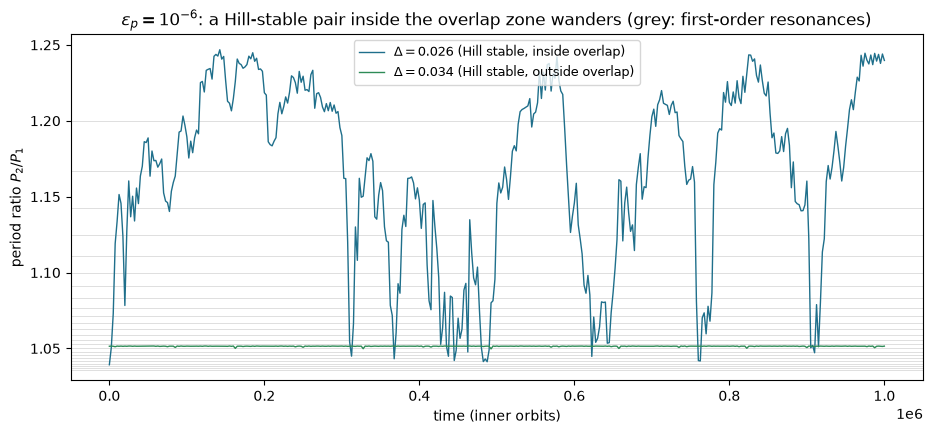

In [7]:
EPS4 = 1e-6
N4 = 2e5 if QUICK else 1e6
print(f"Hill boundary Delta = {ov.hill_delta_circular(EPS4):.4f},  overlap edge Delta = {ov.overlap_delta_circular(EPS4):.4f}")

runs = [(EPS4, 0.026, N4), (EPS4, 0.034, N4)]
t0 = time.time()
with Pool(2) as pool:
    histories = pool.starmap(ov.period_ratio_history, runs)
print(f"done in {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(11, 4.5))
for (eps, delta, _), (t, ratio, dE), col in zip(runs, histories, ["#1f6f8b", "#2e8b57"]):
    inside = "inside" if delta < ov.overlap_delta_circular(eps) else "outside"
    ax.plot(t, ratio, color=col, lw=1, label=rf"$\Delta = {delta}$ (Hill stable, {inside} overlap)")
    print(f"Delta = {delta}: period ratio {ratio.min():.4f} to {ratio.max():.4f}; |dE/E| = {dE:.1e}")
for j in range(5, 40):
    p = (j + 1) / j
    if 1.035 < p < 1.30:
        ax.axhline(p, color="0.85", lw=0.6, zorder=0)
ax.set_xlabel("time (inner orbits)")
ax.set_ylabel("period ratio $P_2/P_1$")
ax.set_title(r"$\epsilon_p = 10^{-6}$: a Hill-stable pair inside the overlap zone wanders (grey: first-order resonances)")
ax.legend(fontsize=9)
plt.show()

The pair outside the overlap zone keeps its period ratio, apart from small regular oscillations. The pair inside it, though Hill stable, drifts through a whole range of period ratios: it is Lagrange unstable.

This matters for interpreting real systems. A pair of observed planets is expected to be dynamically settled, not caught mid-wander, so the overlap criterion, rather than the Hill criterion, is the more useful stability test for close, low-mass, nearly circular pairs.

## Summary

* First-order resonances crowd together as $1/m^2$ and widen as $m^{1/3}$, so close enough to $P_2/P_1 = 1$ they must overlap.
* For two planets on initially circular orbits, overlap and widespread chaos set in for $(a_2-a_1)/a_1 \lesssim 1.46\,\epsilon_p^{2/7}$. This depends only on the total planet mass, not the mass ratio.
* A direct MEGNO map at $\epsilon_p = 2\times10^{-5}$ shows the zone of complete overlap, the chaotic web beyond it, and the growth of chaos with eccentricity.
* Across $10^{-7} < \epsilon_p < 10^{-3}$, the numerically measured edge of chaos follows the $\epsilon_p^{2/7}$ law. It crosses the Hill boundary near $\epsilon_p \approx 3\times10^{-5}$.
* Below that mass, some Hill-stable pairs are chaotic, and their period ratios wander: Hill stability is not enough.

## Going Further

* **Mass ratio.** Add a `mass_ratio` argument to the grid in Section 2 (for example 0.1 or 10). The paper predicts, and found numerically, that the chaotic structure barely changes.
* **Eccentric outer planet.** The theory says only the weighted eccentricity $\sigma$ matters, not $e_1$ and $e_2$ separately. Test it.
* **Longer integrations.** MEGNO can only flag chaos that appears within the run. Increase `N_ORBITS` and watch faint chaotic bands, especially around second-order resonances, fill in.
* **Real systems.** Compute $\epsilon_p$ and $\Delta$ for adjacent planet pairs in a catalogue of multi-planet systems, and see where they fall relative to the two boundaries.

## References

* Chirikov, B. V. (1979), Phys. Rep. 52, 263. [ADS](https://ui.adsabs.harvard.edu/abs/1979PhR....52..263C/abstract)
* Deck, K. M., Payne, M. & Holman, M. J. (2013), ApJ 774, 129. [ADS](https://ui.adsabs.harvard.edu/abs/2013ApJ...774..129D/abstract)
* Gladman, B. (1993), Icarus 106, 247. [ADS](https://ui.adsabs.harvard.edu/abs/1993Icar..106..247G/abstract)
* Hadden, S. & Lithwick, Y. (2018), AJ 156, 95. [ADS](https://ui.adsabs.harvard.edu/abs/2018AJ....156...95H/abstract)
* Marchal, C. & Bozis, G. (1982), Celest. Mech. 26, 311. [ADS](https://ui.adsabs.harvard.edu/abs/1982CeMec..26..311M/abstract)
* Cincotta, P. M. & Simó, C. (2000), MEGNO, A&AS 147, 205. [ADS](https://ui.adsabs.harvard.edu/abs/2000A%26AS..147..205C/abstract)
* Rein, H. & Liu, S.-F. (2012), REBOUND, A&A 537, A128. [ADS](https://ui.adsabs.harvard.edu/abs/2012A%26A...537A.128R/abstract)
* Rein, H. & Tamayo, D. (2016), variational equations in REBOUND, MNRAS 459, 2275. [ADS](https://ui.adsabs.harvard.edu/abs/2016MNRAS.459.2275R/abstract)
* Wisdom, J. (1980), AJ 85, 1122. [ADS](https://ui.adsabs.harvard.edu/abs/1980AJ.....85.1122W/abstract)